In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

In [3]:
DATA_DIR = Path("datasets/cicids2017/versions/1/MachineLearningCVE")

print("Czy katalog istnieje:", DATA_DIR.exists())

csv_files = list(DATA_DIR.glob("*.csv"))

print("Liczba znalezionych plików CSV:", len(csv_files))

for file in csv_files:
    print(file.name)

Czy katalog istnieje: True
Liczba znalezionych plików CSV: 8
Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv
Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv
Friday-WorkingHours-Morning.pcap_ISCX.csv
Monday-WorkingHours.pcap_ISCX.csv
Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv
Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv
Tuesday-WorkingHours.pcap_ISCX.csv
Wednesday-workingHours.pcap_ISCX.csv


In [5]:
#Wczytanie plików do df
dataframes = []

for file in csv_files:
    print("Wczytywanie:", file.name)

    df = pd.read_csv(file, low_memory=False)

    dataframes.append(df)

# Połączenie wszystkich plików
data = pd.concat(dataframes, ignore_index=True)

print("Dane zostały załadowane!")
print("Liczba wierszy i kolumn:", data.shape)

display(data.head())

Wczytywanie: Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv
Wczytywanie: Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv
Wczytywanie: Friday-WorkingHours-Morning.pcap_ISCX.csv
Wczytywanie: Monday-WorkingHours.pcap_ISCX.csv
Wczytywanie: Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv
Wczytywanie: Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv
Wczytywanie: Tuesday-WorkingHours.pcap_ISCX.csv
Wczytywanie: Wednesday-workingHours.pcap_ISCX.csv
Dane zostały załadowane!
Liczba wierszy i kolumn: (2830743, 79)


,Destination Port,Flow Duration,Total Fwd Packets,Total Backward Packets,Total Length of Fwd Packets,Total Length of Bwd Packets,Fwd Packet Length Max,Fwd Packet Length Min,Fwd Packet Length Mean,Fwd Packet Length Std,...,min_seg_size_forward,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,Label
0,54865,3,2,0,12,0,6,6,6.0,0.0,...,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
1,55054,109,1,1,6,6,6,6,6.0,0.0,...,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
2,55055,52,1,1,6,6,6,6,6.0,0.0,...,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
3,46236,34,1,1,6,6,6,6,6.0,0.0,...,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
4,54863,3,2,0,12,0,6,6,6.0,0.0,...,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN


In [8]:
data.info()
display(data.isnull().sum().sort_values(ascending=False))

<class 'pandas.DataFrame'>
RangeIndex: 2830743 entries, 0 to 2830742
Data columns (total 79 columns):
 #   Column                        Dtype  
---  ------                        -----  
 0    Destination Port             int64  
 1    Flow Duration                int64  
 2    Total Fwd Packets            int64  
 3    Total Backward Packets       int64  
 4   Total Length of Fwd Packets   int64  
 5    Total Length of Bwd Packets  int64  
 6    Fwd Packet Length Max        int64  
 7    Fwd Packet Length Min        int64  
 8    Fwd Packet Length Mean       float64
 9    Fwd Packet Length Std        float64
 10  Bwd Packet Length Max         int64  
 11   Bwd Packet Length Min        int64  
 12   Bwd Packet Length Mean       float64
 13   Bwd Packet Length Std        float64
 14  Flow Bytes/s                  float64
 15   Flow Packets/s               float64
 16   Flow IAT Mean                float64
 17   Flow IAT Std                 float64
 18   Flow IAT Max                 int

Flow Bytes/s                   1358
 Flow Duration                    0
 Destination Port                 0
 Total Backward Packets           0
Total Length of Fwd Packets       0
                               ... 
Idle Mean                         0
 Idle Std                         0
 Idle Max                         0
 Idle Min                         0
 Label                            0
Length: 79, dtype: int64

In [25]:
# Czyszczenie danych
data.columns = data.columns.str.strip()

data.dropna(how="all", inplace=True)

data.replace([np.inf, -np.inf], np.nan, inplace=True)

duplicates = data.duplicated().sum()

print("Liczba duplikatów:", duplicates)

data.drop_duplicates(inplace=True)

data["Label"] = data["Label"].astype("string").str.strip()

C:\Users\Milana\AppData\Local\Temp\ipykernel_19020\2044584636.py:4: Pandas4Warning: The inplace keyword in DataFrame.dropna is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  data.dropna(how="all", inplace=True)


Liczba duplikatów: 0


C:\Users\Milana\AppData\Local\Temp\ipykernel_19020\2044584636.py:12: Pandas4Warning: The inplace keyword in DataFrame.drop_duplicates is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  data.drop_duplicates(inplace=True)


In [17]:
class_counts = data["Label"].value_counts()

display(class_counts)

Label
BENIGN                        2096484
DoS Hulk                       172849
DDoS                           128016
PortScan                        90819
DoS GoldenEye                   10286
FTP-Patator                      5933
DoS slowloris                    5385
DoS Slowhttptest                 5228
SSH-Patator                      3219
Bot                              1953
Web Attack � Brute Force         1470
Web Attack � XSS                  652
Infiltration                       36
Web Attack � Sql Injection         21
Heartbleed                         11
Name: count, dtype: int64

In [19]:
class_percentages = data["Label"].value_counts(normalize=True) * 100

display(class_percentages.round(2))

Label
BENIGN                        83.12
DoS Hulk                       6.85
DDoS                           5.08
PortScan                       3.60
DoS GoldenEye                  0.41
FTP-Patator                    0.24
DoS slowloris                  0.21
DoS Slowhttptest               0.21
SSH-Patator                    0.13
Bot                            0.08
Web Attack � Brute Force       0.06
Web Attack � XSS               0.03
Infiltration                   0.00
Web Attack � Sql Injection     0.00
Heartbleed                     0.00
Name: proportion, dtype: float64

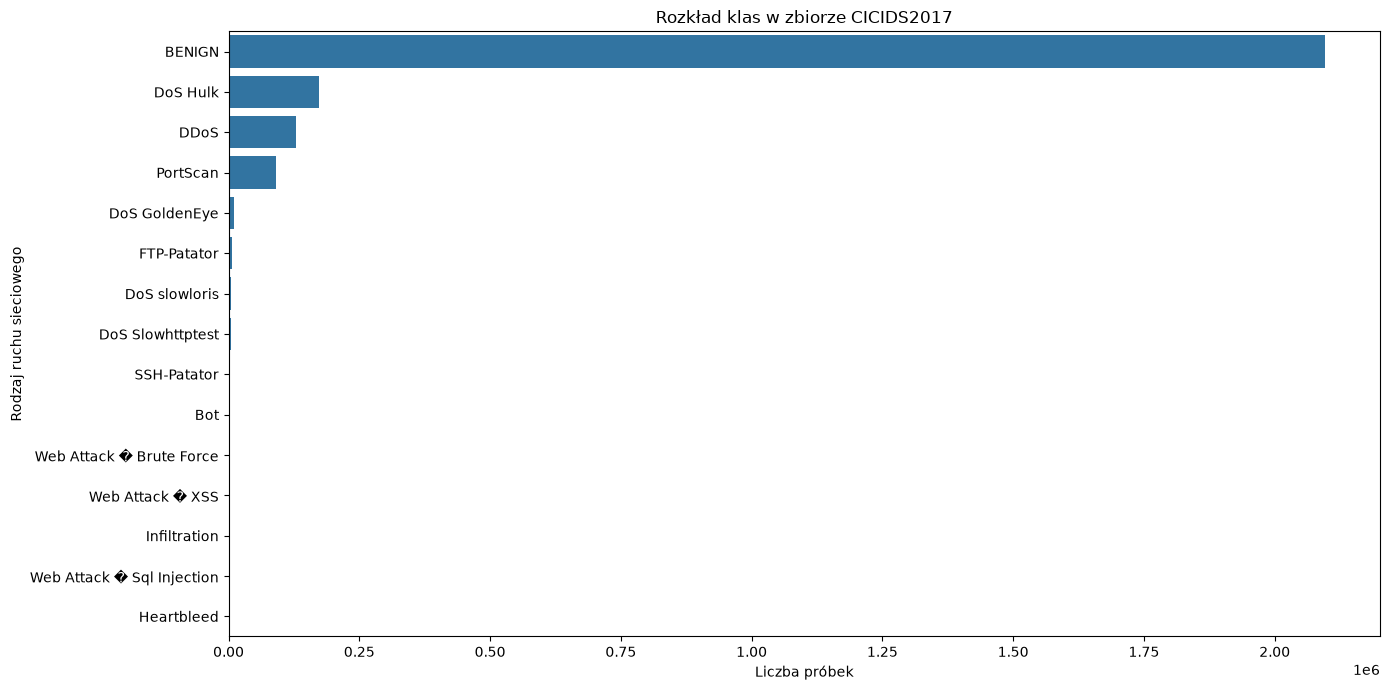

In [22]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(14, 7))

sns.countplot(
    data=data,
    y="Label",
    order=data["Label"].value_counts().index
)

plt.title("Rozkład klas w zbiorze CICIDS2017")
plt.xlabel("Liczba próbek")
plt.ylabel("Rodzaj ruchu sieciowego")

plt.tight_layout()
plt.show()

Analiza rozkładu klas w zbiorze CICIDS2017

W ramach wstępnej analizy zbioru CICIDS2017 przeprowadzono analizę liczebności poszczególnych klas ruchu sieciowego. Zbiór zawiera 15 różnych klas, obejmujących zarówno ruch prawidłowy (BENIGN), jak i różne rodzaje ataków sieciowych.

Analiza wykazała znaczną nierównowagę liczebności klas. Największą grupę stanowi ruch prawidłowy BENIGN, obejmujący 2 096 484 rekordy. Wśród ataków najliczniej reprezentowane są DoS Hulk (172 849 rekordów), DDoS (128 016 rekordów) oraz PortScan (90 819 rekordów).

Najmniej liczne klasy to Heartbleed (11 rekordów), Web Attack – SQL Injection (21 rekordów) oraz Infiltration (36 rekordów).

Zaobserwowana nierównowaga klas jest istotnym czynnikiem, który należy uwzględnić podczas przygotowania danych do procesu uczenia maszynowego. W szczególności może ona wpływać na zdolność klasyfikatora do prawidłowego rozpoznawania rzadziej występujących ataków sieciowych.